<a href="https://colab.research.google.com/github/Josephbello64/online-retail-sales-analysis/blob/main/online_retail_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
print(os.listdir('/content'))

['.config', 'online_retail_II.xlsx', 'sample_data']


In [2]:
import pandas as pd

sheets = pd.read_excel('/content/online_retail_II.xlsx', sheet_name=None)
print(sheets.keys())

dict_keys(['Year 2009-2010', 'Year 2010-2011'])


In [3]:
df = pd.concat(sheets.values(), ignore_index=True)
df.to_csv('/content/retail.csv', index=False)
print(df.shape)

(1067371, 8)


In [4]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [6]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,1.067371e+06,1067371,1.067371e+06,824364.000000
mean,9.938898e+00,2011-01-02 21:13:55.394028544,4.649388e+00,15324.638504
min,-8.099500e+04,2009-12-01 07:45:00,-5.359436e+04,12346.000000
25%,1.000000e+00,2010-07-09 09:46:00,1.250000e+00,13975.000000
50%,3.000000e+00,2010-12-07 15:28:00,2.100000e+00,15255.000000
75%,1.000000e+01,2011-07-22 10:23:00,4.150000e+00,16797.000000
max,8.099500e+04,2011-12-09 12:50:00,3.897000e+04,18287.000000
std,1.727058e+02,NaN,1.235531e+02,1697.464450


In [7]:
print((df['Quantity'] < 0).sum())

22950


In [8]:
df[df['Quantity'] < 0].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom


In [9]:
df[df['Price'] <= 0].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom


In [10]:
df['Invoice'] = df['Invoice'].astype(str)

is_cancel = df['Invoice'].str.startswith('C')
is_adjust = (df['Price'] <= 0) & ~is_cancel

returns = df[is_cancel].copy()
adjustments = df[is_adjust].copy()
sales = df[~is_cancel & ~is_adjust].copy()

print("Sales rows:", len(sales))
print("Return rows:", len(returns))
print("Adjustment rows:", len(adjustments))
print("Sales rows with quantity of 0 or less:", (sales['Quantity'] <= 0).sum())

Sales rows: 1041670
Return rows: 19494
Adjustment rows: 6207
Sales rows with quantity of 0 or less: 0


In [11]:
sales['Revenue'] = sales['Quantity'] * sales['Price']
returns['Revenue'] = returns['Quantity'] * returns['Price']

print("Total sales revenue:", round(sales['Revenue'].sum(), 2))
print("Total returns:", round(returns['Revenue'].sum(), 2))
sales.nlargest(5, 'Price')[['Invoice', 'StockCode', 'Description', 'Quantity', 'Price']]


Total sales revenue: 20972594.57
Total returns: -1526667.86


,Invoice,StockCode,Description,Quantity,Price
241827,512771,M,Manual,1,25111.09
517955,537632,AMAZONFEE,AMAZON FEE,1,13541.33
540478,537632,AMAZONFEE,AMAZON FEE,1,13541.33
825443,A563185,B,Adjust bad debt,1,11062.06
135013,502263,M,Manual,1,10953.50


In [12]:
is_product = sales['StockCode'].astype(str).str.match(r'^\d{5}')

non_products = sales[~is_product]

summary = non_products.groupby(['StockCode', 'Description']).agg(
    rows=('Revenue', 'size'),
    revenue=('Revenue', 'sum')
).sort_values('revenue', ascending=False)

print(summary.head(25))

                                                  rows     revenue
StockCode    Description                                          
M            Manual                                876  340716.280
DOT          DOTCOM POSTAGE                       1436  322657.480
POST         POSTAGE                              1886  127597.420
AMAZONFEE    AMAZON FEE                              4   34009.130
C2           CARRIAGE                              272   13676.000
B            Adjust bad debt                         1   11062.060
ADJUST       Adjustment by john on 26/01/2010 17    16    6563.500
             Adjustment by john on 26/01/2010 16    20    2334.430
ADJUST2      Adjustment by Peter on Jun 25 2010      3     731.050
gift_0001_30 Dotcomgiftshop Gift Voucher £30.00     24     610.090
BANK CHARGES Bank Charges                           33     504.241
gift_0001_20 Dotcomgiftshop Gift Voucher £20.00     26     471.060
D            Discount                                5     397

In [13]:
codes_to_remove = ['M', 'DOT', 'POST', 'AMAZONFEE', 'C2', 'B', 'ADJUST',
                   'ADJUST2', 'BANK CHARGES', 'D', 'TEST001', 'S']

is_gift = sales['StockCode'].astype(str).str.startswith('gift_')
is_junk = sales['StockCode'].isin(codes_to_remove) | is_gift

sales_clean = sales[~is_junk].copy()

print("Rows removed:", is_junk.sum())
print("Rows left:", len(sales_clean))
print("Revenue left:", round(sales_clean['Revenue'].sum(), 2))

still_odd = sales_clean[~sales_clean['StockCode'].astype(str).str.match(r'^\d{5}')]
print(still_odd['StockCode'].value_counts().head(15))


Rows removed: 4643
Rows left: 1037027
Revenue left: 20110197.07
StockCode
DCGS0058     30
DCGSSGIRL    23
DCGSSBOY     21
PADS         17
DCGS0076     15
DCGS0003     13
m             5
DCGS0069      5
DCGS0004      4
DCGS0072      3
DCGS0068      2
DCGS0066N     2
DCGS0070      2
SP1002        2
DCGS0044      1
Name: count, dtype: int64


In [14]:
check = sales_clean[sales_clean['StockCode'].isin(['m', 'PADS', 'SP1002'])]
check[['Invoice', 'StockCode', 'Description', 'Quantity', 'Price', 'Revenue']]

,Invoice,StockCode,Description,Quantity,Price,Revenue
62299,494914,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.001
74731,496222,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.001
77702,496473,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.001
79794,496643,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.001
90798,497935,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.001
96608,498492,m,Manual,1,2.550,2.550
96609,498492,m,Manual,1,3.400,3.400
97716,498562,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.001
101718,499056,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.001
104480,499399,PADS,PADS TO MATCH ALL CUSHIONS,1,0.001,0.001


In [15]:
sales_clean = sales_clean[~sales_clean['StockCode'].isin(['m', 'PADS'])].copy()

print("Rows left:", len(sales_clean))
print("Revenue left:", round(sales_clean['Revenue'].sum(), 2))

sales_clean.to_csv('/content/sales_clean.csv', index=False)

print("Rows with no Customer ID:", sales_clean['Customer ID'].isna().sum())
print("Revenue from those rows:", round(sales_clean[sales_clean['Customer ID'].isna()]['Revenue'].sum(), 2))

Rows left: 1037005
Revenue left: 20110182.0
Rows with no Customer ID: 234370
Revenue from those rows: 2675716.27


In [16]:
sales_clean['Month'] = sales_clean['InvoiceDate'].dt.to_period('M').astype(str)

sales_cust = sales_clean.dropna(subset=['Customer ID']).copy()
sales_cust['Customer ID'] = sales_cust['Customer ID'].astype(int)

print("Rows with a customer:", len(sales_cust))
print("Different customers:", sales_cust['Customer ID'].nunique())

monthly = sales_clean.groupby('Month')['Revenue'].sum().round(0)
print(monthly)

Rows with a customer: 802635
Different customers: 5852
Month
2009-12     801104.0
2010-01     613851.0
2010-02     539745.0
2010-03     764334.0
2010-04     648994.0
2010-05     645645.0
2010-06     699316.0
2010-07     634897.0
2010-08     676061.0
2010-09     871878.0
2010-10    1098018.0
2010-11    1435680.0
2010-12    1187158.0
2011-01     671933.0
2011-02     508886.0
2011-03     691258.0
2011-04     516218.0
2011-05     741192.0
2011-06     738752.0
2011-07     689364.0
2011-08     725514.0
2011-09    1030475.0
2011-10    1106670.0
2011-11    1457746.0
2011-12     615493.0
Name: Revenue, dtype: float64


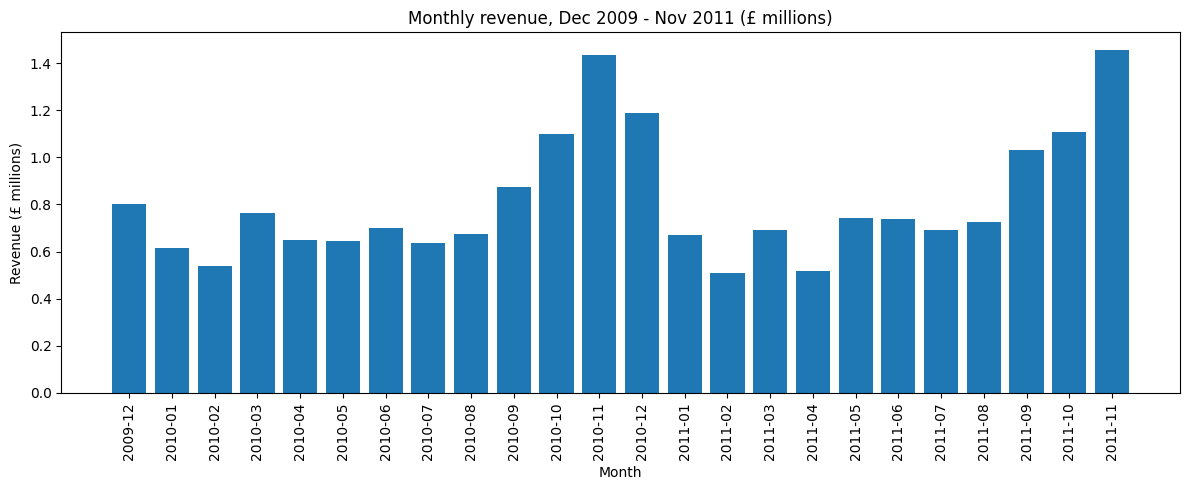

In [17]:
import matplotlib.pyplot as plt

monthly_full = monthly.drop('2011-12')

plt.figure(figsize=(12, 5))
plt.bar(monthly_full.index, monthly_full.values / 1e6)
plt.xticks(rotation=90)
plt.title('Monthly revenue, Dec 2009 - Nov 2011 (£ millions)')
plt.xlabel('Month')
plt.ylabel('Revenue (£ millions)')
plt.tight_layout()
plt.savefig('/content/monthly_revenue.png', dpi=150)
plt.show()

In [18]:
top_products = (sales_clean.groupby('Description')['Revenue']
                .sum()
                .sort_values(ascending=False)
                .head(10)
                .round(0))
print(top_products)

Description
REGENCY CAKESTAND 3 TIER               344563.0
WHITE HANGING HEART T-LIGHT HOLDER     266924.0
PAPER CRAFT , LITTLE BIRDIE            168470.0
JUMBO BAG RED RETROSPOT                150936.0
PARTY BUNTING                          149187.0
ASSORTED COLOUR BIRD ORNAMENT          132188.0
PAPER CHAIN KIT 50'S CHRISTMAS         123142.0
CHILLI LIGHTS                           85490.0
MEDIUM CERAMIC TOP STORAGE JAR          81701.0
ROTATING SILVER ANGELS T-LIGHT HLDR     74449.0
Name: Revenue, dtype: float64


In [19]:
by_country = sales_clean.groupby('Country')['Revenue'].sum().sort_values(ascending=False)
share = (by_country / by_country.sum() * 100).round(1)

print(by_country.head(10).round(0))
print()
print("Share of total revenue (%):")
print(share.head(10))


Country
United Kingdom    17233902.0
EIRE                628929.0
Netherlands         549953.0
Germany             388830.0
France              316949.0
Australia           168485.0
Spain                98613.0
Switzerland          94270.0
Sweden               86353.0
Denmark              68560.0
Name: Revenue, dtype: float64

Share of total revenue (%):
Country
United Kingdom    85.7
EIRE               3.1
Netherlands        2.7
Germany            1.9
France             1.6
Australia          0.8
Spain              0.5
Switzerland        0.5
Sweden             0.4
Denmark            0.3
Name: Revenue, dtype: float64


In [20]:
name = 'PAPER CRAFT , LITTLE BIRDIE'

print("Sales:")
print(sales_clean[sales_clean['Description'] == name][['Invoice', 'Quantity', 'Price', 'Revenue']])

print("Returns:")
print(returns[returns['Description'] == name][['Invoice', 'Quantity', 'Price', 'Revenue']])

Sales:
        Invoice  Quantity  Price   Revenue
1065882  581483     80995   2.08  168469.6
Returns:
         Invoice  Quantity  Price   Revenue
1065883  C581484    -80995   2.08 -168469.6


In [21]:
junk_codes = codes_to_remove + ['m', 'PADS']

returns_clean = returns[
    ~(returns['StockCode'].astype(str).isin(junk_codes) |
      returns['StockCode'].astype(str).str.startswith('gift_'))
].copy()

net = pd.concat([sales_clean, returns_clean])

top_net = (net.groupby('Description')['Revenue']
           .sum()
           .sort_values(ascending=False)
           .head(10)
           .round(0))

print(top_net)
print("Total net revenue:", round(net['Revenue'].sum(), 2))

Description
REGENCY CAKESTAND 3 TIER               327814.0
WHITE HANGING HEART T-LIGHT HOLDER     257534.0
JUMBO BAG RED RETROSPOT                148801.0
PARTY BUNTING                          147948.0
ASSORTED COLOUR BIRD ORNAMENT          131414.0
PAPER CHAIN KIT 50'S CHRISTMAS         121662.0
CHILLI LIGHTS                           84854.0
ROTATING SILVER ANGELS T-LIGHT HLDR     73815.0
BLACK RECORD COVER FRAME                69247.0
JUMBO BAG STRAWBERRY                    69054.0
Name: Revenue, dtype: float64
Total net revenue: 19375729.18


In [22]:
net_cust = net.dropna(subset=['Customer ID']).copy()
net_cust['Customer ID'] = net_cust['Customer ID'].astype(int)

by_customer = net_cust.groupby('Customer ID')['Revenue'].sum().sort_values(ascending=False)

print("Top 10 customers (£):")
print(by_customer.head(10).round(0))

top10_share = by_customer.head(10).sum() / by_customer.sum() * 100
print()
print("Top 10 customers' share of customer revenue (%):", round(top10_share, 1))

orders = net_cust[net_cust['Quantity'] > 0].groupby('Customer ID')['Invoice'].nunique()
print()
print("Customers with only 1 order:", (orders == 1).sum())
print("Customers with 2 or more orders:", (orders >= 2).sum())

Top 10 customers (£):
Customer ID
18102    606243.0
14646    523203.0
14156    298276.0
14911    262863.0
17450    235833.0
13694    191196.0
17511    171899.0
12415    143107.0
16684    141530.0
15061    136412.0
Name: Revenue, dtype: float64

Top 10 customers' share of customer revenue (%): 16.2

Customers with only 1 order: 1618
Customers with 2 or more orders: 4234
